# Querétaro Airbnb market — exploratory analysis

**Business question:** where do price, occupancy and revenue concentrate in the Querétaro short-term-rental market, and what can a 100-listing sample actually support?

**Scope.** 100 Airbnb listings in Santiago de Querétaro, Mexico, published by [AirROI's public data portal](https://www.airroi.com/data-portal/markets/queretaro-mexico) in the 2026-07 release. One rural farm stay 47 km from the centro is retained in the data but excluded from city-level statistics (**n = 99**).

**Important:** this is a **representative 100-listing sample**, not the full market. AirROI reports ~1,700 active listings in the city; none of the figures below should be read as market totals.

**Contents**

1. Setup and data provenance
2. Sample profile
3. What does a night cost?
4. Does location matter?
5. Seasonality and repricing
6. Segments: room type, superhost, management
7. Revenue concentration
8. Correlation overview
9. Limitations

## 1. Setup and data provenance

In [1]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent

DATA = PROJECT / "data" / "processed"
FIGURES = PROJECT / "reports" / "figures"


def show(filename, width=920):
    display(Image(filename=str(FIGURES / filename), width=width))


listings = pd.read_csv(DATA / "listings.csv", dtype={"listing_id": str, "postal_code": str})
rates = pd.read_csv(DATA / "monthly_rates.csv", dtype={"listing_id": str}, parse_dates=["month_start"])
quality = json.loads((DATA / "data_quality.json").read_text(encoding="utf-8"))
metrics = json.loads((PROJECT / "reports" / "key_metrics.json").read_text(encoding="utf-8"))

city = listings[listings["is_city_core"]].copy()
monthly = rates[rates["listing_id"].isin(city["listing_id"])].copy()

print(f"raw listings: {len(listings)} | city sample: {len(city)} | monthly rows: {len(monthly)}")
print(f"period: {monthly['month_start'].min():%b %Y} to {monthly['month_start'].max():%b %Y}")
print(f"checks passed: {sum(c['status'] == 'pass' for c in quality['checks'])}/{len(quality['checks'])}")

raw listings: 100 | city sample: 99 | monthly rows: 1183
period: Aug 2025 to Jul 2026
checks passed: 24/24


### Provenance

| Item | Value |
|---|---|
| Source | AirROI public Data Portal — Querétaro market |
| Release | 2026-07 (`temporalCoverage` 2012-01 → 2026-07) |
| Downloaded | 2026-10-25 |
| Licence | CC BY-NC 4.0 (attribution, non-commercial) |
| Files | `listings` (100 × 72), `past_rates` (1,195 monthly rows), `reviews` (532 rows) |
| Geography | Santiago de Querétaro; 1 rural farm stay flagged and excluded |
| Currency | MXN (native); USD fields also present |

Inside Airbnb was checked first. As of 2026-10-25 its Mexico coverage contains only Mexico City, so no Inside Airbnb Querétaro snapshot exists. See `data/README.md` for the source log and the licence caveat.

In [2]:
checks = pd.DataFrame(quality["checks"])[["check", "status", "detail"]]
checks["detail"] = checks["detail"].str.wrap(80)
checks

,check,status,detail
0,listings file parses,pass,"100 rows, 73 fields"
1,rates file parses,pass,"1195 rows, 14 fields"
2,listing_id is unique,pass,100 unique ids for 100 rows
3,listing_id is numeric,pass,all ids are digit strings (Airbnb listing ids)
4,currency is MXN,pass,values: ['MXN']
5,coordinates within Querétaro state bbox,pass,"lat 20.5622..20.6874, lon -100.4462..-99.9378"
6,nightly price positive,pass,min 362.4 MXN
7,"occupancy within [0, 1]",pass,range 0.027..0.663
8,reserved + available = total calendar days,pass,100/100 listings consistent; AirROI 'blocked' days are a subset of 'available'\ndays
9,adjusted occupancy = reserved / (total - blocked),pass,max absolute difference 0.0005 (provider rounds to 3 dp)


In [3]:
missing = (
    listings[["bedrooms", "guests", "rating_overall", "location_is_exact", "has_description", "price_per_guest_mxn"]]
    .isna().sum()
    .to_frame("missing")
)
missing["pct"] = (missing["missing"] / len(listings) * 100).round(1)
missing

,missing,pct
bedrooms,19,19.0
guests,19,19.0
rating_overall,1,1.0
location_is_exact,6,6.0
has_description,0,0.0
price_per_guest_mxn,19,19.0


The pipeline runs 24 validation checks; all pass. Two data-quality findings matter for interpretation:

* **Bedrooms are missing for 19 of 100 listings** — 17 of those are private rooms. Airbnb does not expose bedroom metadata consistently for shared-room inventory, so "unknown" is structural, not random. Any bedroom analysis therefore covers 80 listings.
* **AirROI's `blocked` days are a subset of `available` days.** `occupancy` (reserved / all calendar nights) and `adjusted_occupancy` (reserved / nights the host left open) answer different questions. This notebook uses calendar occupancy, and says so.

## 2. Sample profile

In [4]:
sample = pd.Series(metrics["sample"]).to_frame("value")
display(sample)

head = pd.DataFrame(metrics["headline"]).T
ci = pd.DataFrame(metrics["bootstrap_ci_95"]).T[["low", "high"]]
ci.columns = ["median_ci_low", "median_ci_high"]
head = head.join(ci)
head[["n", "median", "median_ci_low", "median_ci_high", "p25", "p75", "mean"]].round(3)

,value
listings_total,100.000000
listings_city,99.000000
rural_outliers,1.000000
hosts,50.000000
superhosts,55.000000
professionally_managed,17.000000
professional_hosts,2.000000
entire_homes,75.000000
private_rooms,24.000000
within_1km_pct,51.515152


,n,median,median_ci_low,median_ci_high,p25,p75,mean
price_mxn,99.0,1029.200,831.6,1159.8,657.950,1357.800,1302.909
occupancy,99.0,0.241,0.181,0.315,0.099,0.424,0.265
adjusted_occupancy,99.0,0.278,0.196875,0.362,0.127,0.532,0.319
revenue_mxn,99.0,87335.000,54273.0,116516.0,36594.000,184562.000,121170.313
revpar_mxn,99.0,233.000,148.7,289.5,96.000,485.900,318.391


**Reading the confidence intervals.** The 95% bootstrap CI for median ADR is **MX$832–1,160** and for median occupancy **18.1%–31.5%**. Those intervals describe sampling uncertainty *within this 100-listing sample*. They do **not** describe the full market, because the sample was not drawn with a known probability design.

The sample skews central (51.5% within 1 km of Plaza de Armas) and toward entire homes (76%). Both facts are limitations, not findings.

## 3. What does a night cost?

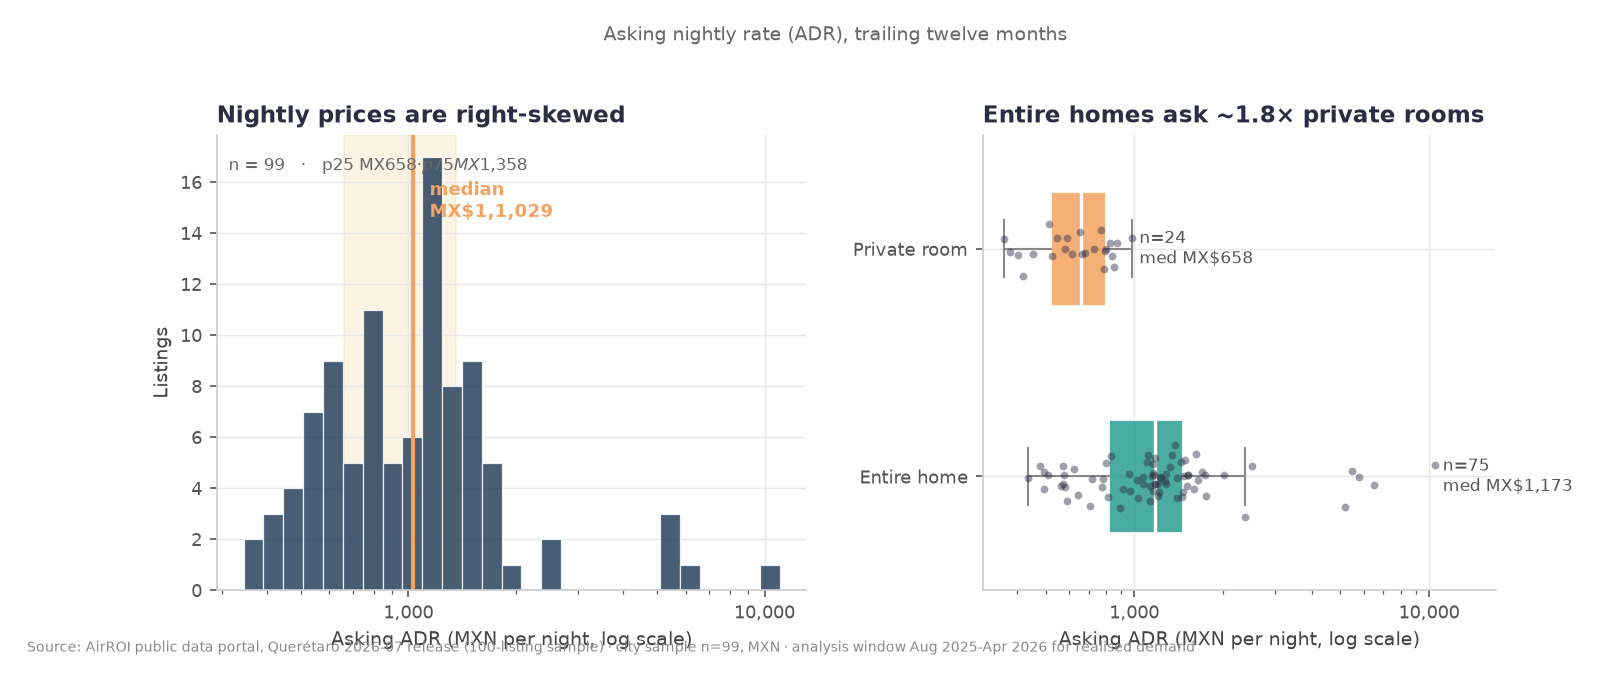

In [5]:
show('01_price_distribution.png')

The median asking rate is **MX$1,029 per night** (IQR MX$658–1,358), but the distribution has a long right tail: the top decile starts at MX$1,742 and the maximum is MX$10,497 for a 9-bedroom home.

Entire homes ask a median **MX$1,173**, private rooms **MX$658** — a **1.78×** gap. The gap is statistically visible (Mann–Whitney p < 0.001, Cliff's δ = 0.70), but it is also confounded with capacity: private rooms are smaller and more likely to omit bedroom metadata.

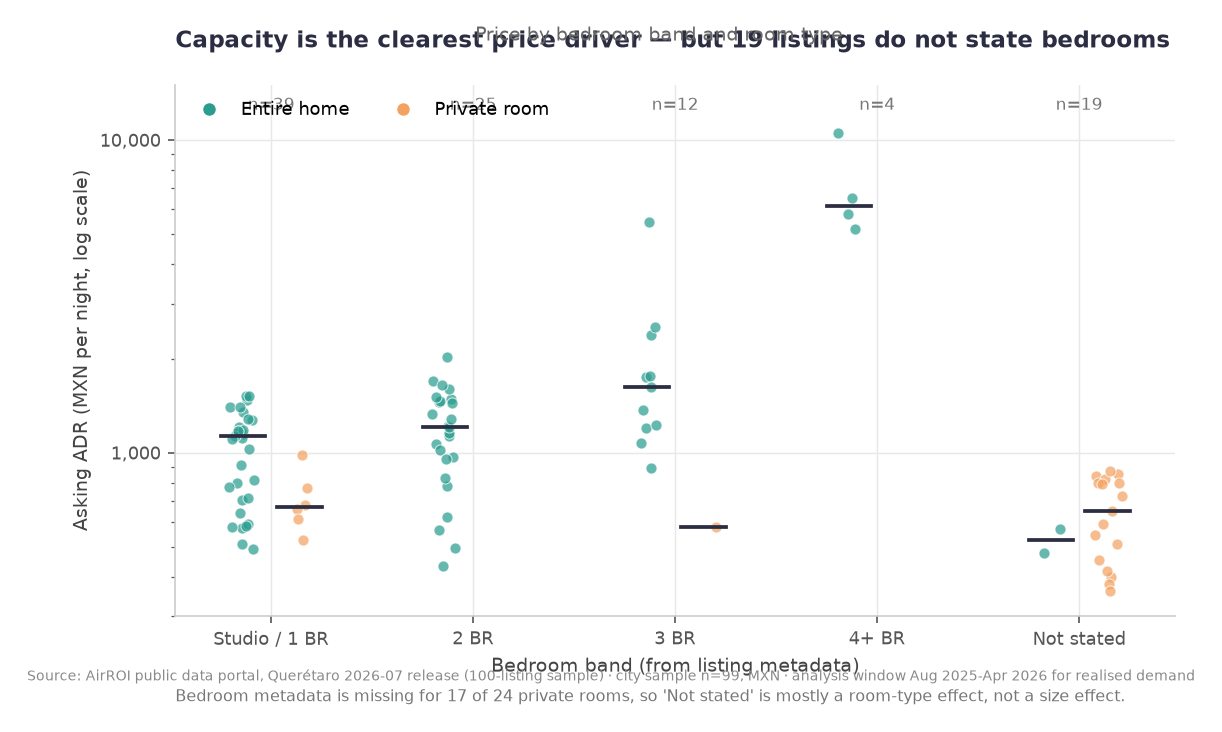

,listings,median_adr,mean_occupancy,median_revenue
bedroom_band,,,,
Studio / 1 BR,39,1029.2,0.30,102070.0
2 BR,25,1205.7,0.31,129697.0
3 BR,12,1493.6,0.25,101242.5
4+ BR,4,6155.7,0.18,345821.5


In [6]:
by_bed = (
    city[city["bedroom_band"] != "Unknown"]
    .groupby("bedroom_band")
    .agg(listings=("listing_id", "size"), median_adr=("price_mxn", "median"),
         mean_occupancy=("occupancy", "mean"), median_revenue=("revenue_mxn", "median"))
    .reindex(["Studio / 1 BR", "2 BR", "3 BR", "4+ BR"])
)
show('02_capacity_and_price.png')
by_bed.round(2)

Capacity is the clearest price driver in the cross-section: Spearman ρ = **0.57** with guest count and **0.47** with bedrooms (n = 80). The four 4+ bedroom listings ask a mean MX$6,998/night but run at 18% occupancy — high ticket, low volume. Their revenue is still the highest of any band because a few bookings at a very high nightly rate dominate.

Note the "Unknown" band: it is 19 listings, mostly private rooms, and its MX$593 median is a room-type artefact rather than a size effect.

## 4. Does location matter?

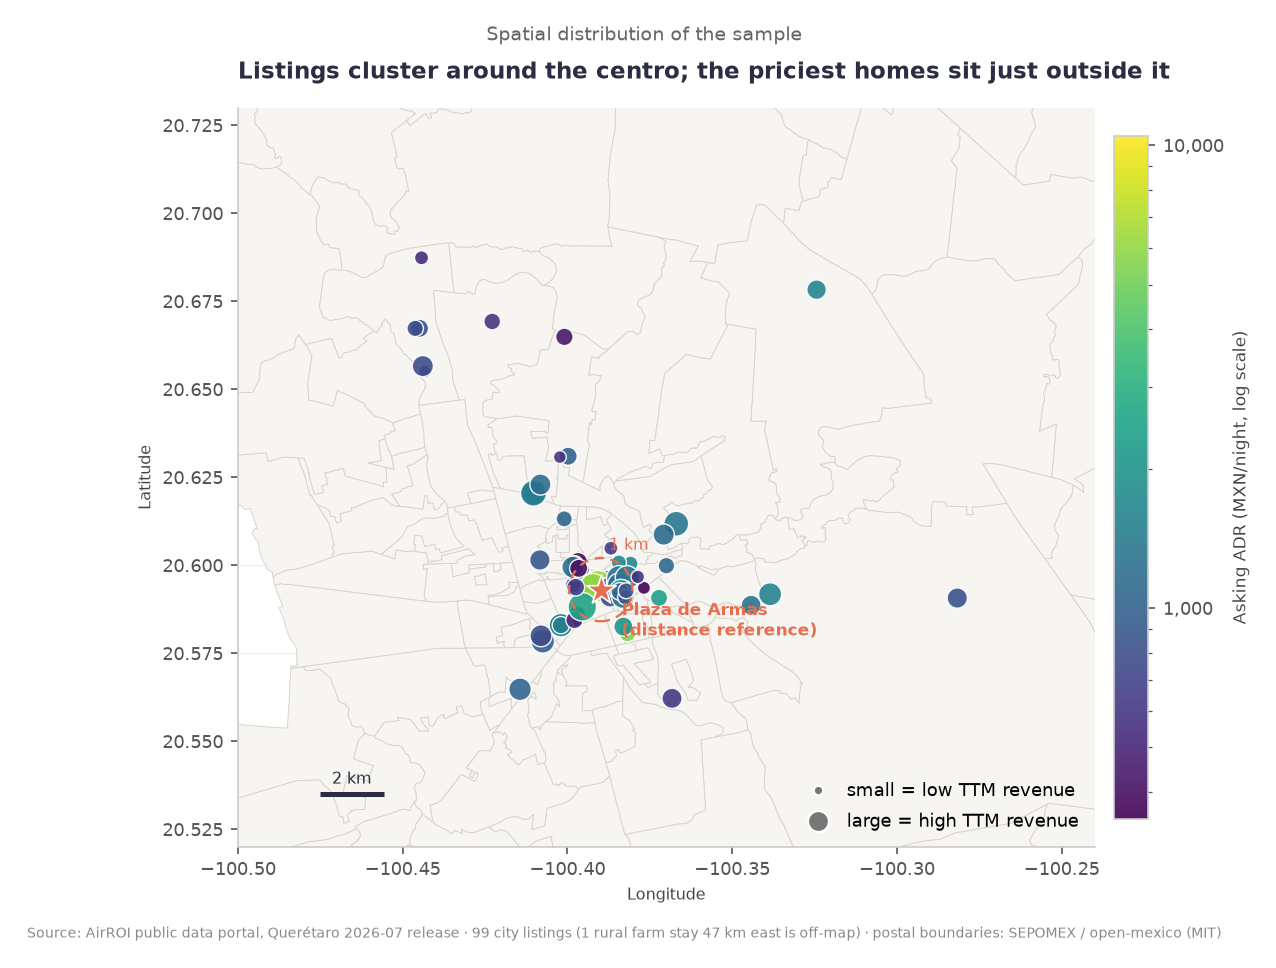

In [7]:
show('03_listing_map.png')

The sample is concentrated around the centro. The map uses asking ADR for colour and trailing-twelve-month revenue for bubble size. Two patterns are visible before any statistics:

* The historic centre and the immediate ring contain most listings, at mixed price points.
* The largest bubbles (highest revenue) are large homes just outside the centro — not the cheapest or the most central listings.

The map is a **sample**, not a census. Postal boundaries come from SEPOMEX (via `open-mexico/mexico-geojson`, MIT); they are postal areas, not neighbourhoods.

Spearman rho (distance vs ADR): -0.013 (p=0.90)


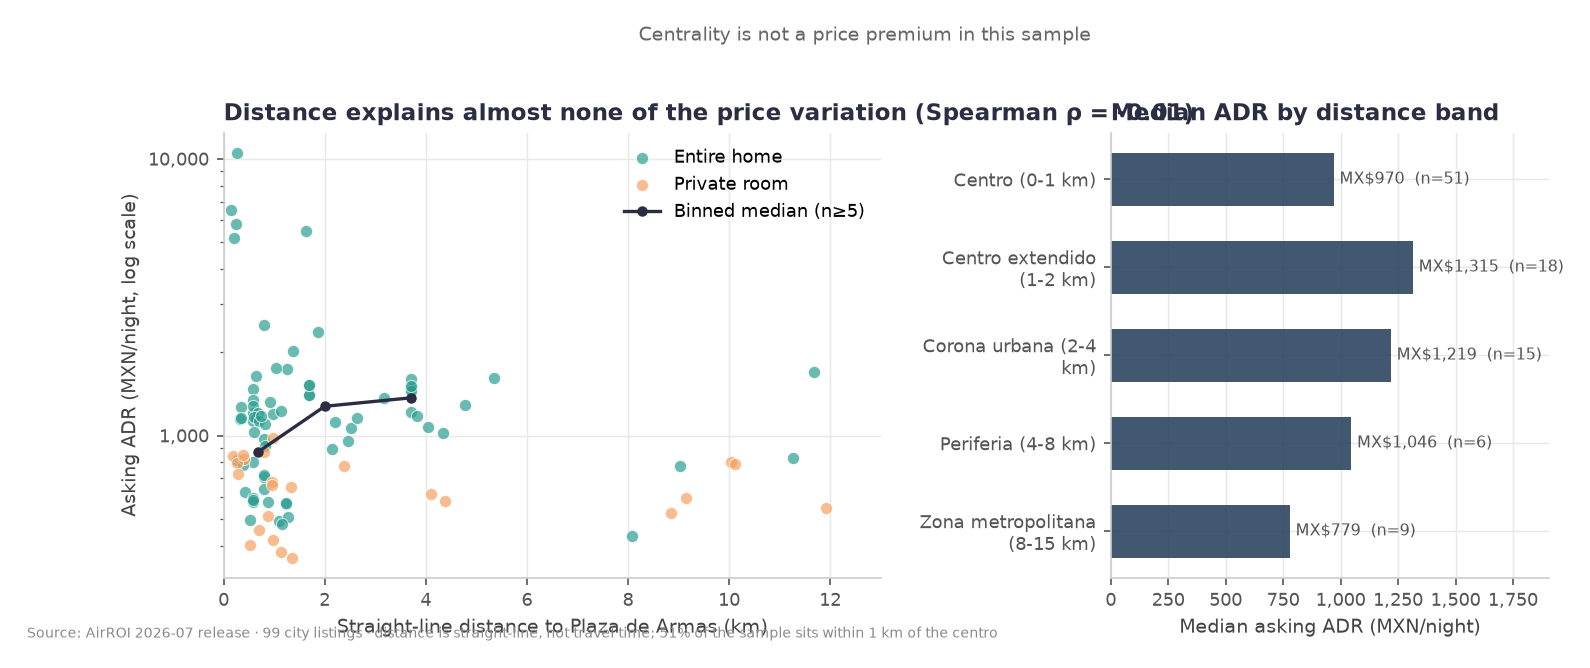

In [8]:
key = "price_mxn__distance_centro_km"
print(f"Spearman rho (distance vs ADR): {metrics['correlations'][key]['spearman_rho']:+.3f} "
      f"(p={metrics['correlations'][key]['p_value']:.2f})")
show('04_distance_and_price.png')

**Centrality is not a price premium in this sample.** The rank correlation between distance to Plaza de Armas and asking ADR is **−0.01** (p = 0.90).

The band medians look non-monotonic — MX$970 within 1 km, MX$1,315 at 1–2 km, MX$1,219 at 2–4 km, MX$779 at 8–15 km — because each band mixes different property sizes. The 1–2 km band contains several large homes; the 8–15 km band is mostly private rooms in the northwest. With 5–51 listings per band, these are descriptive differences, not location effects.

A better location model would need neighbourhood fixed effects, walkability or travel time. The data does not support that.

## 5. Seasonality and repricing

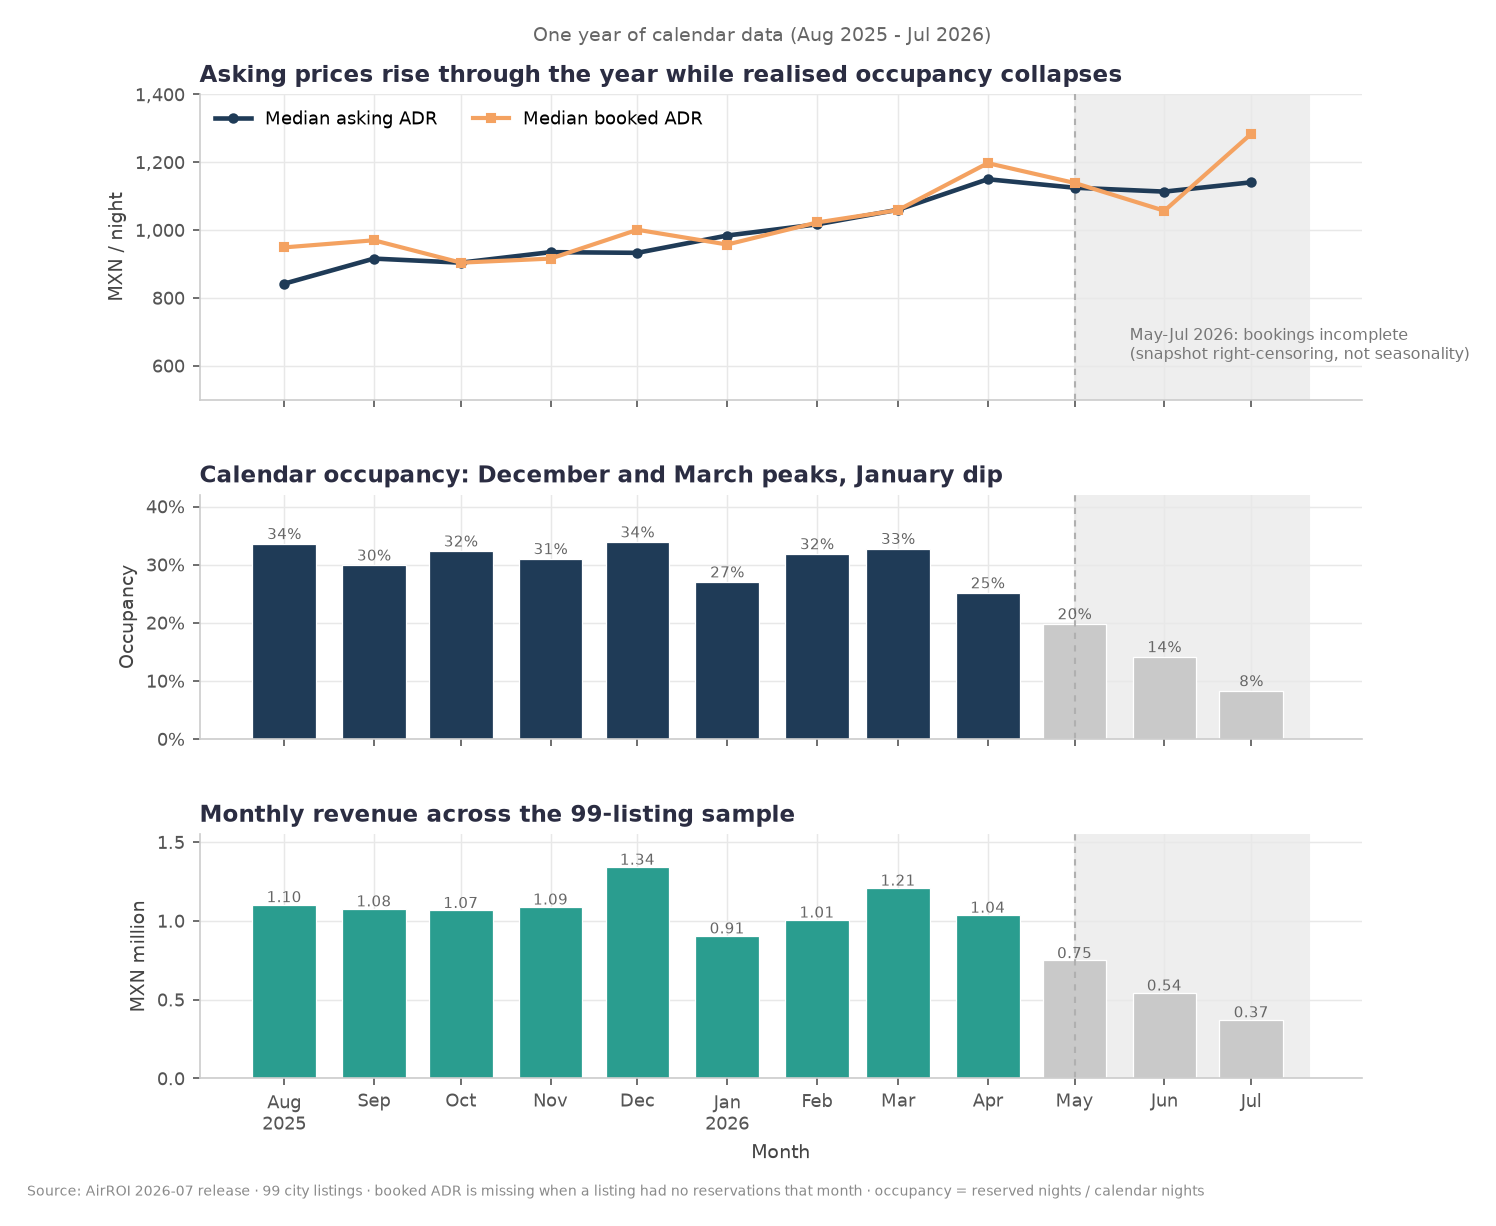

In [9]:
show('05_seasonality.png')

The 12-month calendar shows a clear **December peak**: 33.9% occupancy and MX$1.34M revenue across the sample, versus a January dip (27.0%, MX$0.91M) and a weaker April (25.1%).

**But the last three months are not usable for demand claims.** Review volume collapses from ~100/month to 73 (May), 25 (June), 6 (July). That is the signature of a data snapshot taken before bookings and reviews for those months had accumulated. The grey band in the figure marks the censored window; every realised-demand statement in this project is restricted to **Aug 2025–Apr 2026**.

In [10]:
months = pd.DataFrame(metrics["seasonality"]["months"])
months["occupancy"] = (months["occupancy"] * 100).round(1)
months.rename(columns={"occupancy": "occupancy_pct"}, inplace=True)
months

C:\Users\Rafae\AppData\Local\Temp\ipykernel_7960\1623544798.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  months.rename(columns={"occupancy": "occupancy_pct"}, inplace=True)


,month,occupancy_pct,median_adr_quoted,median_adr_booked,revenue_mxn
0,2025-08,33.6,842.0,949.0,1104260.0
1,2025-09,29.9,916.0,970.0,1077486.0
2,2025-10,32.3,904.0,904.0,1067247.0
3,2025-11,31.0,935.0,916.0,1089135.0
4,2025-12,33.9,933.0,1001.0,1342015.0
5,2026-01,27.0,984.0,957.5,905670.0
6,2026-02,31.8,1017.0,1022.5,1006751.0
7,2026-03,32.8,1060.0,1059.0,1209558.0
8,2026-04,25.1,1150.0,1197.5,1037661.0


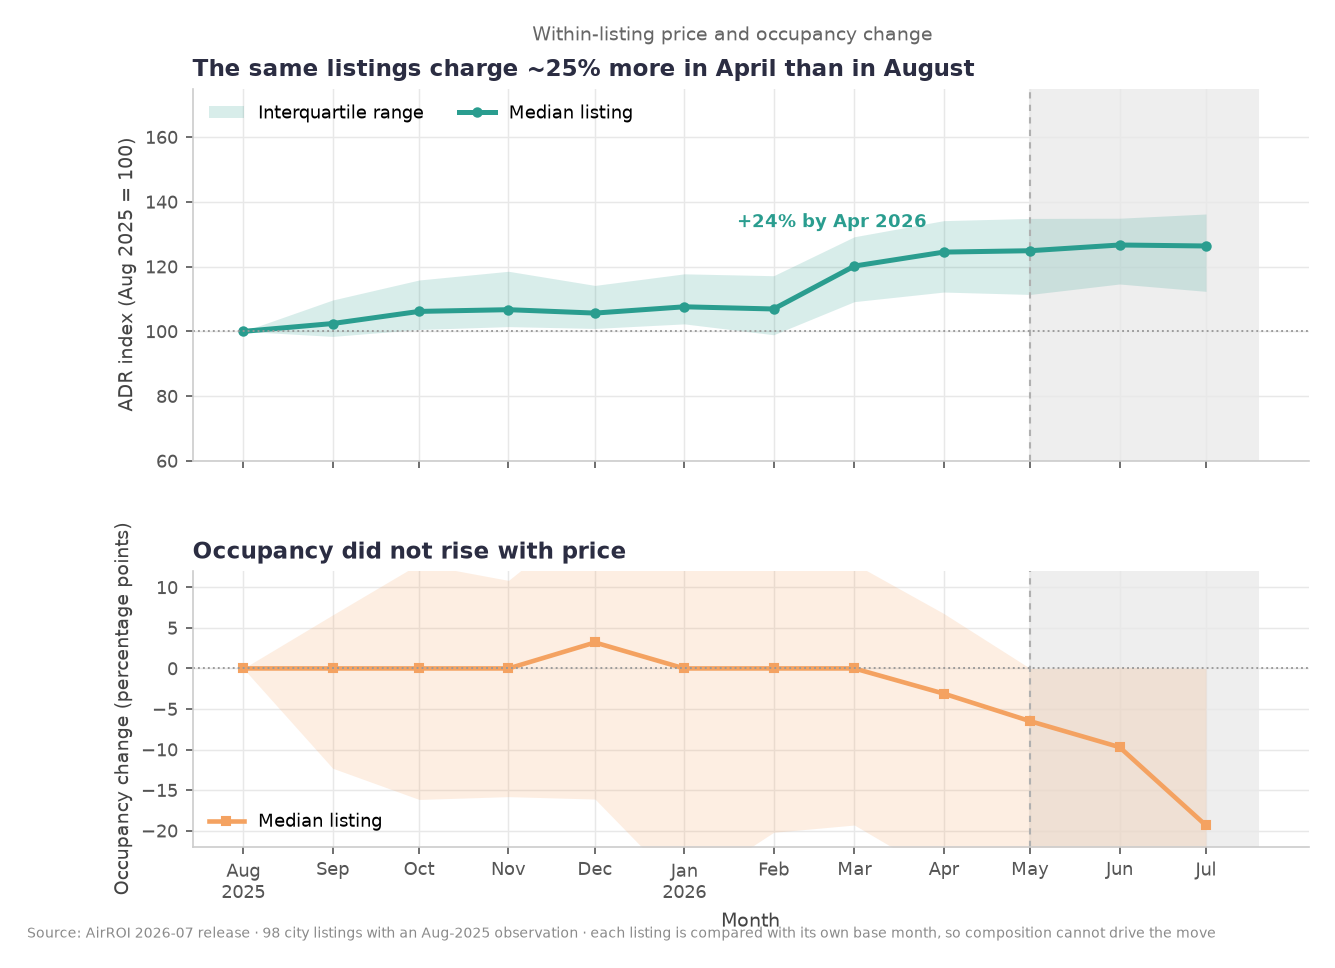

In [11]:
show('10_within_listing_repricing.png')

The monthly median can move because the mix of listings changes. The within-listing view removes that: each listing is compared with **its own August 2025 asking rate**.

* **94% of the 98 listings with an August observation raised their asking ADR** by April 2026.
* The median increase is **+24.5%** (mean +26.0%), far above Mexican consumer inflation over the same period.
* Median occupancy fell about **3 percentage points** over the same window, so the repricing did not come with higher demand.

This is the most interesting pattern in the dataset — and the one that most needs a longer window. Nine months cannot distinguish a structural repricing trend from seasonal spring pricing. I would not extrapolate it to an annual growth rate.

## 6. Segments: room type, superhost, management

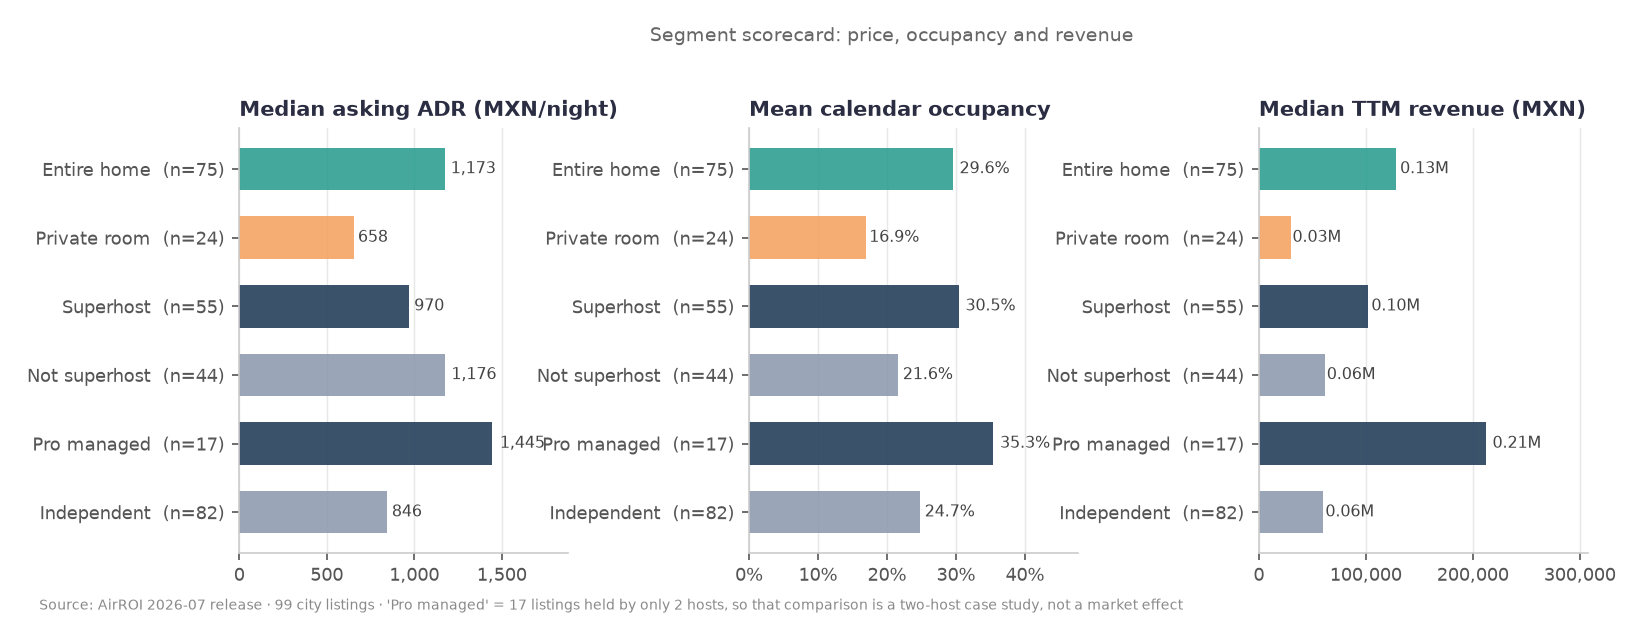

In [12]:
show('07_segment_scorecard.png')

In [13]:
rows = []
for test in metrics["tests"]:
    for metric in ["price_mxn", "occupancy", "revenue_mxn"]:
        r = test[metric]
        rows.append({
            "segment comparison": test["comparison"],
            "metric": metric,
            "median A": round(r["group_a_median"], 3),
            "median B": round(r["group_b_median"], 3),
            "ratio A/B": round(r["ratio_a_to_b"], 2),
            "Mann-Whitney p": f"{r['mann_whitney_p']:.4f}",
            "Cliff's delta": round(r["cliffs_delta"], 2),
        })
pd.DataFrame(rows)

,segment comparison,metric,median A,median B,ratio A/B,Mann-Whitney p,Cliff's delta
0,entire_home vs private_room,price_mxn,1172.800,657.950,1.78,0.0000,0.70
1,entire_home vs private_room,occupancy,0.307,0.125,2.46,0.0016,0.43
2,entire_home vs private_room,revenue_mxn,128135.000,30492.000,4.20,0.0000,0.68
3,superhost vs not,price_mxn,970.000,1176.500,0.82,0.3259,-0.12
4,superhost vs not,occupancy,0.315,0.179,1.75,0.0138,0.29
5,superhost vs not,revenue_mxn,102070.000,61629.500,1.66,0.2139,0.15
6,professionally managed vs independent,price_mxn,1445.300,846.250,1.71,0.0000,0.63
7,professionally managed vs independent,occupancy,0.353,0.195,1.81,0.0150,0.38
8,professionally managed vs independent,revenue_mxn,212004.000,60345.000,3.51,0.0001,0.59


Three exploratory comparisons, in order of how much I trust them:

1. **Entire home vs private room** — large, consistent gap in price, occupancy and revenue. Confounded by capacity, but the direction is robust.
2. **Superhost vs not** — superhosts ask *less* (median MX$970 vs MX$1,177; p = 0.33) but are booked more often (31.5% vs 18.0%; p = 0.014). Revenue is higher in the median (MX$102k vs MX$62k) but the difference is not statistically clear (p = 0.21). The badge looks like an occupancy signal, not a price premium.
3. **Professional management vs independent** — the largest apparent gap (3.5× median revenue), but **17 "professionally managed" listings belong to just two hosts**. This is a two-host case study, not evidence about management companies. It is reported for transparency and should not be generalized.

With ~100 observations and many comparisons, p-values are exploratory. Effect sizes and the underlying distributions matter more.

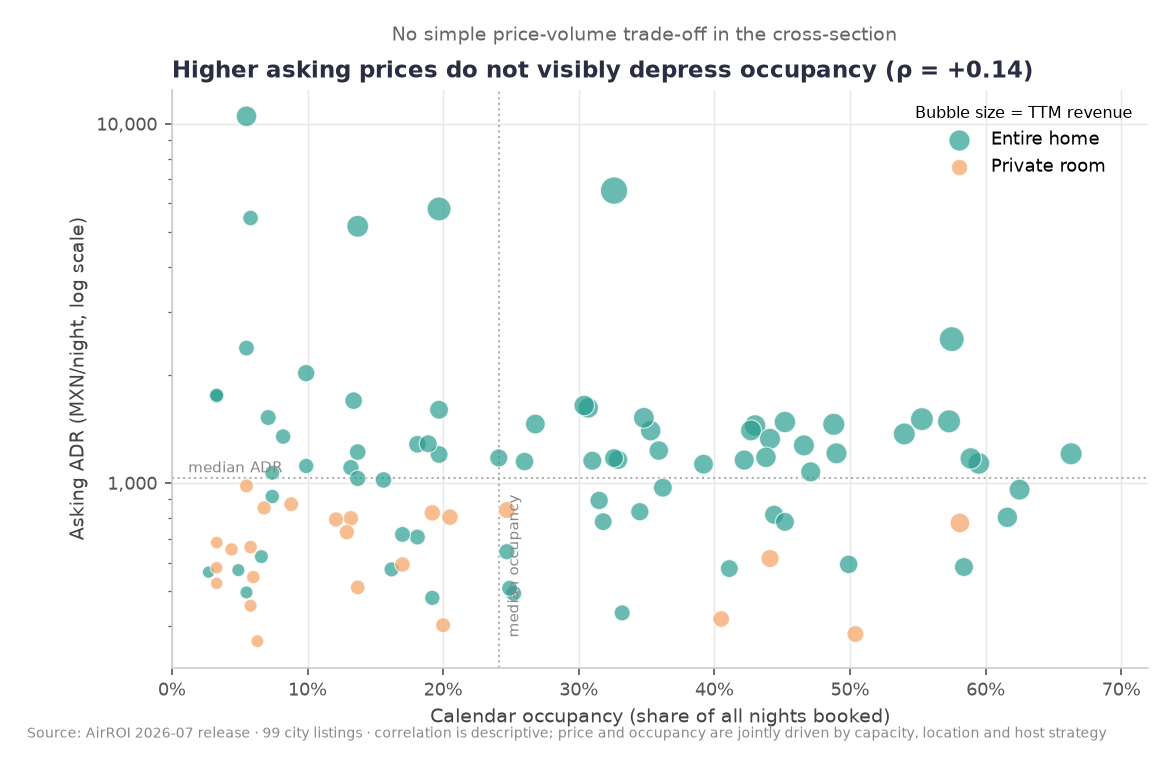

In [14]:
show('06_price_vs_occupancy.png')

There is no visible price–volume trade-off: the rank correlation between asking ADR and occupancy is **+0.14** (p = 0.16), i.e. essentially flat. In a cross-section of heterogeneous listings, a high price does not mechanically produce low occupancy — capacity, location and host strategy move both variables.

This is exactly why the project avoids estimating revenue-maximising prices. Doing that credibly needs listing-level panel variation and a demand model, not a scatter plot of 99 listings.

## 7. Revenue concentration

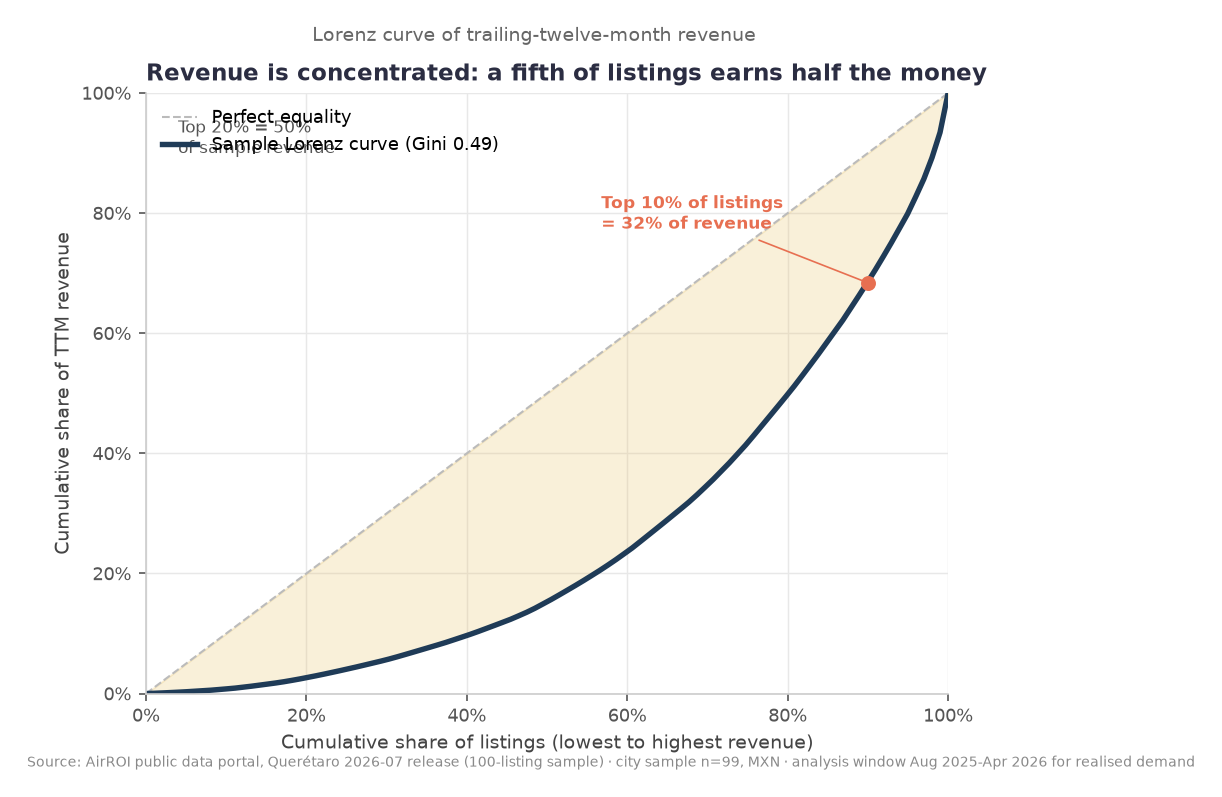

In [15]:
show('08_revenue_concentration.png')

Revenue is concentrated: the top **10%** of listings earn **31.6%** of sample revenue, the top **20%** earn **50.5%**, and the top half earn **85.1%**. The Gini coefficient is **0.49**.

The largest single host operates 11 listings and accounts for **18.9%** of sample revenue. That is a structural feature of the sample and a warning: any "average host" statistic is really an average over a market with a long tail of single-listing hosts and a small group of multi-listing operators.

## 8. Correlation overview

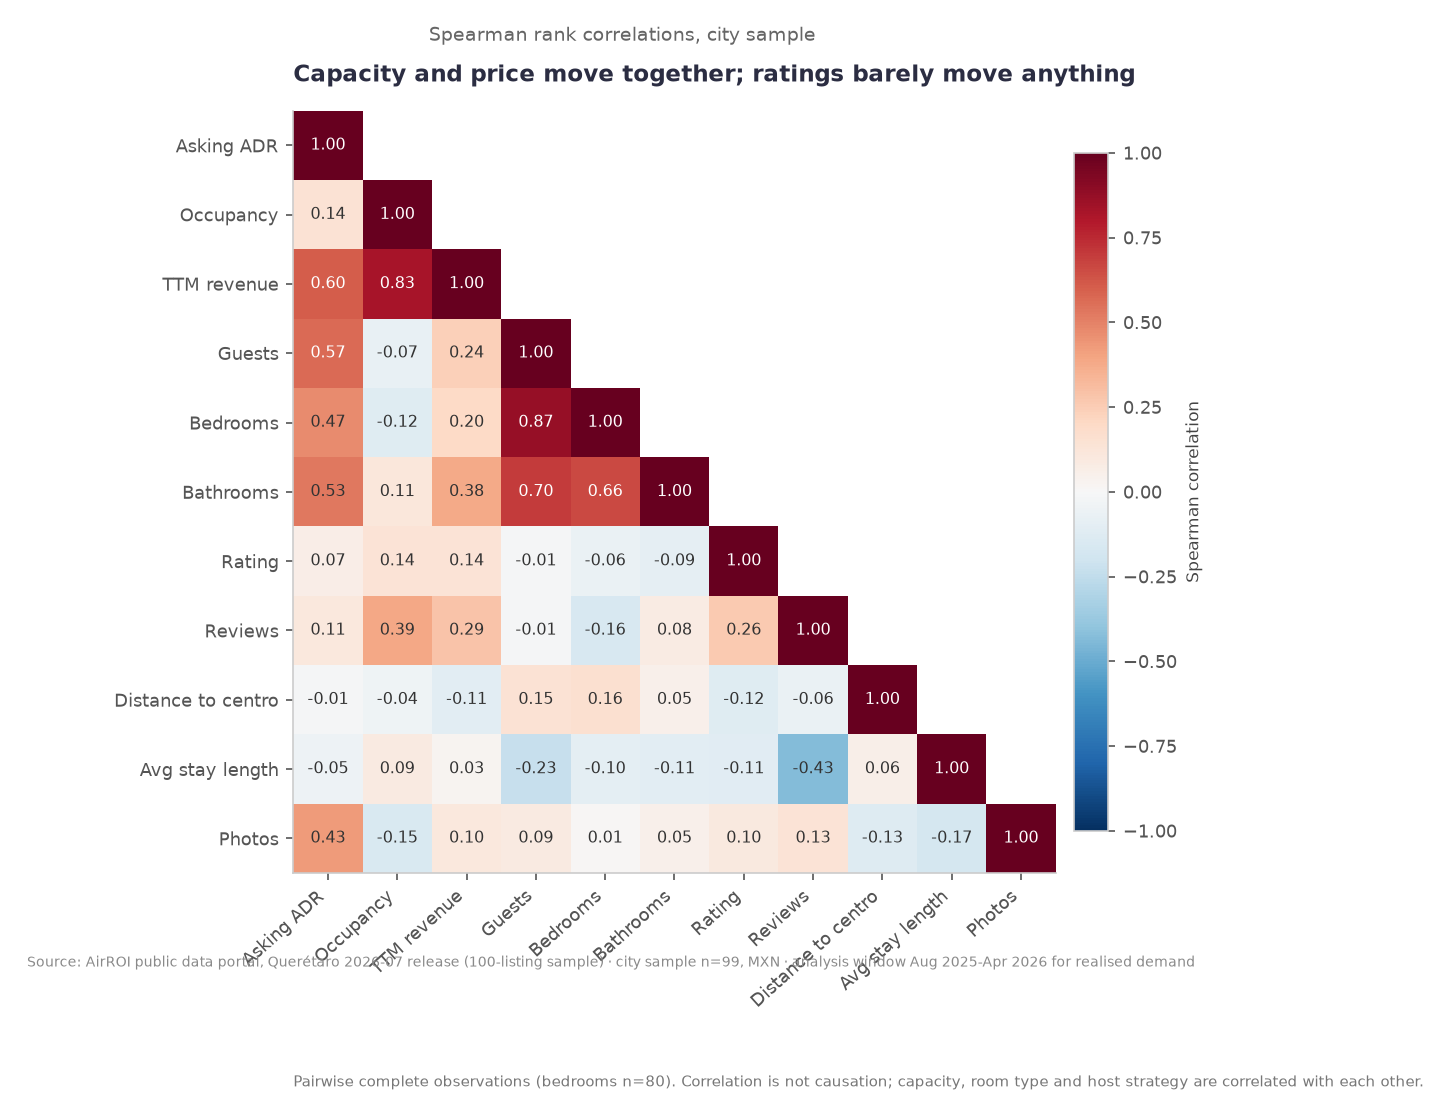

In [16]:
show('09_correlation_matrix.png')

The correlation matrix summarises the descriptive structure:

* **Capacity** (guests, bedrooms, bathrooms) is the strongest correlate of price, and capacity variables are highly correlated with each other.
* **Occupancy** is the dominant correlate of revenue (ρ = 0.83) — more than price (ρ = 0.60).
* **Ratings** are compressed (median 4.83) and barely correlate with price (ρ = 0.07) or occupancy (ρ = 0.14). A 4.8 vs 4.9 rating is not a meaningful price lever in this sample.
* **Distance to centro** is essentially uncorrelated with price.

Correlation is not causation, and the pairwise sample sizes differ (bedrooms are available for 80 listings).

## 9. Limitations

**Sampling**
* 100 listings out of ~1,700 active Querétaro listings. Not a probability sample.
* 51.5% of listings sit within 1 km of the centro; suburban and rural inventory is under-represented.
* 76% entire homes vs 24% private rooms.

**Measurement**
* AirROI data is modelled/observed calendar data, not a raw Airbnb scrape. The exact extraction methodology is not public.
* `native_rate_avg` is a **quoted** rate and is populated even in months with zero bookings. `native_booked_rate_avg` is the realised ADR and is null when there were no bookings. Conflating the two would overstate realised prices.
* Revenue fields include fees: monthly revenue sums to MX$11.51M, while the TTM revenue field sums to MX$12.00M (+4.3%), even though reserved nights match exactly (9,588).
* Calendar occupancy treats host-blocked nights as unbooked. `adjusted_occupancy` nets them out; the two differ materially for some listings (median 24.1% vs 27.8%).

**Time**
* Only 12 months, and the last three are right-censored. No year-over-year comparison is possible.
* The within-listing +24.5% repricing is a 9-month change; seasonality and trend cannot be separated.

**Geography**
* No neighbourhood field. Distance to Plaza de Armas is a straight-line proxy; postal codes are official areas, not colonias.
* Coordinates are approximate for 55 listings (`exact_location = false`).

**Causality**
* Every segment comparison is observational. Superhost status, professional management, price and occupancy are jointly determined.
* No occupancy/revenue estimate is made for listings outside the sample, and no revenue-maximising price is claimed.

**What I would do next**
1. Buy or request the full listing universe from AirROI and reweight to the market.
2. Add neighbourhood polygons with official colonia boundaries and estimate a hedonic model with fixed effects.
3. Extend the calendar to 24–36 months to separate seasonality from trend.
4. Model booked ADR and occupancy jointly, with host fixed effects, before making any pricing recommendation.